<a href="https://colab.research.google.com/github/Hossain-Mahmud00/cantera-projects/blob/main/TCS_Distillation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install thermo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.4/6.4 MB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.3/22.3 MB 36.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.8/608.8 kB 20.4 MB/s eta 0:00:00


In [3]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from thermo import Chemical

tcs = Chemical('10025-78-2')   # trichlorosilane, SiHCl3
stc = Chemical('10026-04-7')   # silicon tetrachloride, SiCl4

for c in (tcs, stc):
    print(c.name, c.formula, round(c.Tb, 1), c.Tc, c.Pc)

trichlorosilane Cl3HSi 306.1 479.0 4054013.0
tetrachlorosilane Cl4Si 330.8 507.0 3749025.0


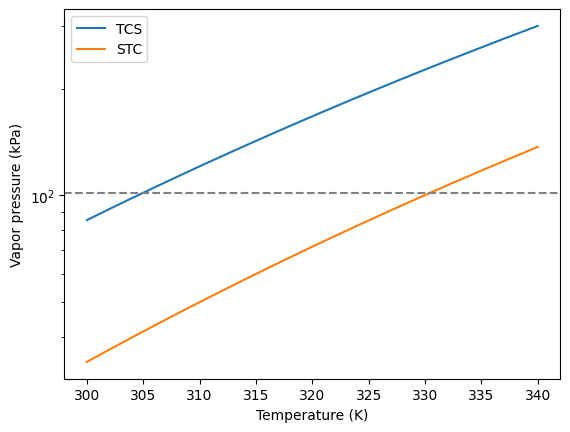

alpha at 300 K: 2.5102092432314977
alpha at 340 K: 2.1929391668622857


In [4]:

def Psat(chem, T):
    return chem.VaporPressure.T_dependent_property(T)

Ts = np.linspace(300, 340, 21)
P_tcs = np.array([Psat(tcs, T) for T in Ts]) / 1000
P_stc = np.array([Psat(stc, T) for T in Ts]) / 1000
alpha = P_tcs / P_stc

plt.semilogy(Ts, P_tcs, label='TCS')
plt.semilogy(Ts, P_stc, label='STC')
plt.axhline(101.325, color='gray', linestyle='--')
plt.xlabel('Temperature (K)')
plt.ylabel('Vapor pressure (kPa)')
plt.legend()
plt.show()

print('alpha at 300 K:', alpha[0])
print('alpha at 340 K:', alpha[-1])

Boiling point TCS (K): 304.8851100507701
Boiling point STC (K): 330.3447217633149
Average alpha: 2.3664522977341305


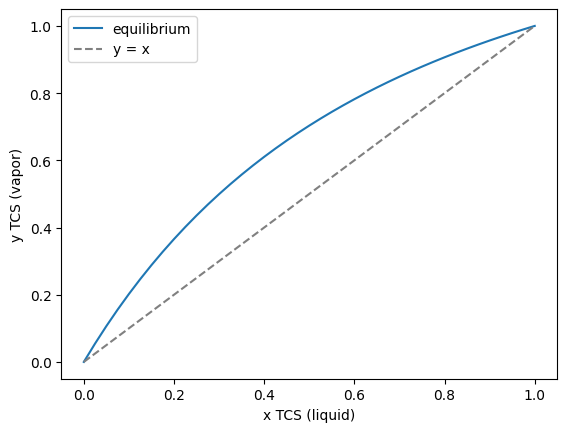

In [5]:

P = 101325

def vle(x):
    f = lambda T: x*Psat(tcs, T) + (1-x)*Psat(stc, T) - P
    T = brentq(f, 300, 340)
    y = x*Psat(tcs, T) / P
    a = Psat(tcs, T) / Psat(stc, T)
    return T, y, a

xs = np.linspace(0, 1, 41)
res = [vle(x) for x in xs]
Tb = np.array([r[0] for r in res])
ys = np.array([r[1] for r in res])
al = np.array([r[2] for r in res])

print('Boiling point TCS (K):', Tb[-1])
print('Boiling point STC (K):', Tb[0])
print('Average alpha:', al.mean())

plt.plot(xs, ys, label='equilibrium')
plt.plot([0, 1], [0, 1], '--', color='gray', label='y = x')
plt.xlabel('x TCS (liquid)')
plt.ylabel('y TCS (vapor)')
plt.legend()
plt.show()

Rmin: 1.4098970635202956  R: 1.8328661825763843
Theoretical stages: 22  feed stage: 11


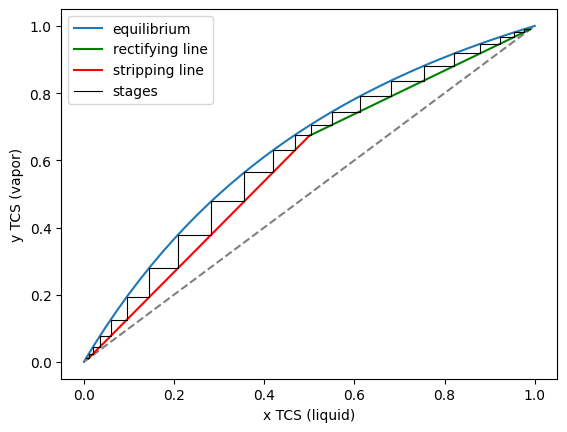

In [6]:

zF, xD, xB = 0.5, 0.99, 0.01

ystar = np.interp(zF, xs, ys)
Rmin = (xD - ystar) / (ystar - zF)
R = 1.3 * Rmin
print('Rmin:', Rmin, ' R:', R)

x_int = zF
y_int = R/(R+1)*zF + xD/(R+1)

def op(x):
    if x >= x_int:
        return R/(R+1)*x + xD/(R+1)
    return xB + (y_int - xB)/(x_int - xB)*(x - xB)

xp, yp = [xD], [xD]
y, n, feed = xD, 0, None
while n < 200:
    x = np.interp(y, ys, xs)
    n += 1
    xp.append(x); yp.append(y)
    if feed is None and x < x_int:
        feed = n
    if x <= xB:
        break
    y = op(x)
    xp.append(x); yp.append(y)

print('Theoretical stages:', n, ' feed stage:', feed)

plt.plot(xs, ys, label='equilibrium')
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.plot([xD, x_int], [xD, y_int], 'g', label='rectifying line')
plt.plot([x_int, xB], [y_int, xB], 'r', label='stripping line')
plt.plot(xp, yp, 'k', linewidth=0.8, label='stages')
plt.xlabel('x TCS (liquid)')
plt.ylabel('y TCS (vapor)')
plt.legend()
plt.show()

In [7]:

alpha_avg = al.mean()
Nmin = np.log((xD/(1-xD)) * ((1-xB)/xB)) / np.log(alpha_avg)
print('Fenske Nmin:', Nmin)

X = (R - Rmin) / (R + 1)
Y = 1 - np.exp((1 + 54.4*X)/(11 + 117.2*X) * (X - 1)/np.sqrt(X))
N = (Y + Nmin) / (1 - Y)
print('Gilliland N:', N)

Fenske Nmin: 10.669057328173045
Gilliland N: 22.6095154456466
